In [1]:
import numpy as np
import torch
import torch.nn as nn
from pathlib import Path
from sklearn.model_selection import train_test_split
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts

from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

import matplotlib.pyplot as plt



from typing import Dict, List, Tuple, Optional, Any, Type


import import_ipynb
import os
curdir = os.getcwd()
src_path = Path('../src/')
os.chdir(src_path)
from BaseDataSet_Gen import plot_dataset_variability
os.chdir(curdir)

In [2]:
E_GRID = np.arange(-10,60.1,0.5)
IN_DIM=141 # Размер входного спектра.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
N_SAMPLES = 128

In [3]:
# Подгружаем данные без аугментаций спектров
X_train = np.load('../processed_data/DataSets/Combined_No_Aug_3A_Train_X.npz')['arr_0']
y_train = np.load('../processed_data/DataSets/Combined_No_Aug_3A_Train_y.npz')['arr_0']

# Подгружаем данные с аугментациями спектров
X_train_aug = np.load('../processed_data/DataSets/Scenario_3_Train_X.npz')['arr_0']
y_train_aug = np.load('../processed_data/DataSets/Scenario_3_Train_y.npz')['arr_0']

indexes = np.arange(X_train.shape[0])
indexes_aug = np.arange(X_train_aug.shape[0])

np.random.seed(SEED)

np.random.shuffle(indexes)
np.random.shuffle(indexes_aug)

X_train = X_train[indexes[:N_SAMPLES]]
y_train = y_train[indexes[:N_SAMPLES]]

X_train_aug = X_train_aug[indexes_aug[:N_SAMPLES]]
y_train_aug = y_train_aug[indexes_aug[:N_SAMPLES]]

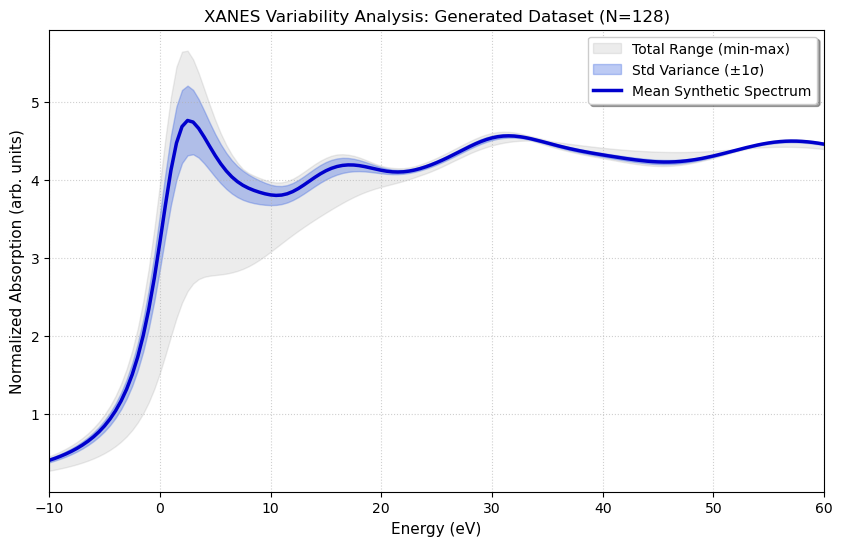

In [4]:
plot_dataset_variability(X_train[:N_SAMPLES],energy_grid=E_GRID)
# plot_dataset_variability(X_train_aug[:N_SAMPLES],energy_grid=E_GRID)

## Блоки для сборки моделей

In [5]:
class BasicResBlock1D(nn.Module):
    def __init__(self, channels: int, kernel_size: int = 5, dropout: float = 0.1):
        super().__init__()
        padding = kernel_size // 2
        self.conv1 = nn.Conv1d(channels, channels, kernel_size=kernel_size, padding=padding, bias=False)
        self.bn1 = nn.BatchNorm1d(channels)
        self.act = nn.GELU()
        
        self.conv2 = nn.Conv1d(channels, channels, kernel_size=kernel_size, padding=padding, bias=False)
        self.bn2 = nn.BatchNorm1d(channels)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = x
        
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.act(out)
        out = self.dropout(out)
        
        out = self.conv2(out)
        out = self.bn2(out)
        
        out += residual
        return self.act(out)

class DownsampleResBlock1D(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, stride: int = 2, kernel_size: int = 5, dropout: float = 0.1):
        super().__init__()
        padding = kernel_size // 2
        
        # Основная ветвь
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.act = nn.GELU()
        
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=kernel_size, stride=1, padding=padding, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.dropout = nn.Dropout(dropout)
        
        # Shortcut с 1x1 сверткой для проекции каналов и шага
        self.shortcut = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
            nn.BatchNorm1d(out_channels)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = self.shortcut(x)
        
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.act(out)
        out = self.dropout(out)
        
        out = self.conv2(out)
        out = self.bn2(out)
        
        out += residual
        return self.act(out)

class ProbabilisticRegressionHead(nn.Module):
    '''
    Голова модели: выдает линейные предсказания для Mu и Log(Variance) 
    для каждого из целевых параметров (num_outputs от 1 до 7).
    '''
    def __init__(self, in_features: int, num_outputs: int):
        super().__init__()
        self.fc_mu = nn.Linear(in_features, num_outputs)
        self.fc_log_var = nn.Linear(in_features, num_outputs)
        
        # Инициализируем голову дисперсии так, чтобы на старте 
        # модель была уверена в прогнозе (sigma ≈ 0.22 -> log_var ≈ -3.0)
        nn.init.constant_(self.fc_log_var.weight, 1e-6)
        nn.init.constant_(self.fc_log_var.bias, -2.0)

    def forward(self, x: torch.Tensor):
        mu = self.fc_mu(x)
        # log_var = torch.zeros_like(mu)
        log_var = self.fc_log_var(x)
        log_var = torch.clamp(log_var, min=-6.0, max=2.5)
        return mu, log_var


class MultiScaleConv1d(nn.Module):
    def __init__(self, in_channels, out_channels):
        '''
        out_channels%3==0
        '''
        super().__init__()
        c_branch = out_channels // 3
        
        self.branch1 = nn.Conv1d(in_channels, c_branch, kernel_size=3, padding=1, bias=False)
        self.branch2 = nn.Conv1d(in_channels, c_branch, kernel_size=7, padding=3, bias=False)
        self.branch3 = nn.Conv1d(in_channels, c_branch, kernel_size=15, padding=7, bias=False)
        
        self.bn = nn.BatchNorm1d(out_channels)
        self.act = nn.GELU()
        
        # Shortcut для стабильности градиентов (если размерности совпадают)
        self.shortcut = nn.Conv1d(in_channels, out_channels, kernel_size=1) if in_channels != out_channels else nn.Identity()

    def forward(self, x):
        res = self.shortcut(x)
        out = torch.cat([self.branch1(x), self.branch2(x), self.branch3(x)], dim=1)
        return self.act(self.bn(out) + res)


class AttentionPooling1d(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.attn_conv = nn.Conv1d(channels, 1, kernel_size=1)
        self.softmax = nn.Softmax(dim=2)
        
    def forward(self, x):
        # x shape: [Batch, Channels, Length]
        weights = self.softmax(self.attn_conv(x)) # [Batch, 1, Length]
        out = torch.sum(x * weights, dim=2)       # [Batch, Channels]
        return out


## Функции потерь

In [6]:
class GaussianNLLLoss(nn.Module):
    def __init__(self, eps: float = 1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, outputs, target: torch.Tensor) -> torch.Tensor:
        if isinstance(outputs, (tuple, list)):
            mu, log_var = outputs
        else:
            mu, log_var = torch.chunk(outputs, chunks=2, dim=-1)
            
        var = torch.exp(log_var) + self.eps
        loss = 0.5 * log_var + 0.5 * ((target - mu) ** 2) / var
        return loss.mean()

class HybridGaussianMSELoss(nn.Module):
    def __init__(self, mse_weight=1.0, mae_weight=1.0, nll_weight=1.0, eps=1e-6):
        super().__init__()
        self.mse_weight = mse_weight
        self.mae_weight = mae_weight
        self.nll_weight = nll_weight
        self.eps = eps
        self.mae = nn.L1Loss()
        self.mse = nn.MSELoss()
        self.nnl_loss = GaussianNLLLoss()

    def forward(self, outputs, target: torch.Tensor) -> torch.Tensor:
        if isinstance(outputs, (tuple, list)):
            mu, log_var = outputs
        else:
            mu, log_var = torch.chunk(outputs, chunks=2, dim=-1)
            
        var = torch.exp(log_var) + self.eps
        nll_loss = self.nnl_loss(outputs, target)
        
        mse_loss = self.mse(mu, target)
        mae_loss = self.mae(mu, target)
        
        # Итоговая взвешенная сумма
        total_loss = self.nll_weight * nll_loss + self.mse_weight * mse_loss + self.mae_weight * mae_loss
        return total_loss

## Модели

In [7]:
class ProbabilisticXANESResNet1D(nn.Module):
    def __init__(self, in_features: int = 141, num_outputs: int = 4, dropout: float = 0.):
        super().__init__()
        
        # Stem: Подготовка входных данных (1 канал -> 32 канала)
        self.stem = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=3, stride=1, padding='same', bias=False),
            nn.BatchNorm1d(32),
            nn.GELU()
        )
        
        # Backbone (Резонансная глубокая часть)
        self.stage1 = BasicResBlock1D(channels=32, kernel_size=3, dropout=dropout)
        self.stage2 = DownsampleResBlock1D(in_channels=32, out_channels=64, stride=2, kernel_size=3, dropout=dropout)
        self.stage3 = DownsampleResBlock1D(in_channels=64, out_channels=128, stride=2, kernel_size=3, dropout=dropout)
        
        # Сжатие и переход к регрессии
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.shared_dense = nn.Sequential(nn.Flatten(),
                                          nn.Linear(128, 64),
                                          nn.GELU(),
                                          nn.Dropout(dropout)
                                         )
        
        self.prob_head = ProbabilisticRegressionHead(in_features=64, num_outputs=num_outputs)

    def forward(self, x: torch.Tensor):
        # Если пришел вектор формы [batch, 141], превращаем в 3D [batch, 1, 141]
        if x.dim() == 2:
            x = x.unsqueeze(1)
            
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        
        x = self.global_pool(x)
        feat = self.shared_dense(x)
        
        mu, log_var = self.prob_head(feat)
        return mu, log_var

In [8]:
class MultiScaleXANESNet(nn.Module):
    def __init__(self, in_features=141, num_outputs=4, channels_out=36, dropout=0.0):
        super().__init__()
        
        # нормализация входа
        self.stem = nn.Sequential(nn.Conv1d(1, 12, kernel_size=5, padding='same', bias=False), 
                                  nn.BatchNorm1d(12), 
                                  nn.GELU()
                                 )
    
        self.ms_block1 = MultiScaleConv1d(12, channels_out) # Выход: 36
        
        self.ms_block2 = MultiScaleConv1d(channels_out, channels_out*3) # Выход: 108 каналов
        total_channels_2 = channels_out * 3
        
        # Агрегация по длине
        self.pool = AttentionPooling1d(total_channels_2)

        self.shared_dense = nn.Sequential(nn.Linear(total_channels_2, 64),
                                          nn.GELU(),
                                          nn.Dropout(dropout),
                                         )
        
        self.prob_head = ProbabilisticRegressionHead(in_features=64, num_outputs=num_outputs)
        
    def forward(self, x):
        # Если вход [Batch, 141], добавляем размерность канала -> [Batch, 1, 141]
        if x.dim() == 2:
            x = x.unsqueeze(1)
            
        x = self.stem(x)
        x = self.ms_block1(x)
        x = self.ms_block2(x)
        
        x = self.pool(x)
        
        feat = self.shared_dense(x)
        mu, log_var = self.prob_head(feat)
        return mu, log_var

In [9]:
class XANES_CNN(nn.Module):
    def __init__(self, in_features, num_outputs=4, kernel_size=3, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(in_channels=1, out_channels=16, kernel_size=kernel_size, padding='same'),
                                 nn.BatchNorm1d(16), 
                                 nn.GELU(), 
                                 nn.Dropout(dropout),
                                 nn.MaxPool1d(2), 
                                 nn.Conv1d(in_channels=16, out_channels=32, kernel_size=kernel_size, padding='same'),
                                 nn.BatchNorm1d(32), 
                                 nn.GELU(), 
                                 nn.Dropout(dropout),
                                 nn.MaxPool1d(2), 
                                 nn.Conv1d(in_channels=32, out_channels=64, kernel_size=kernel_size, padding='same'),
                                 nn.BatchNorm1d(64), 
                                 nn.GELU(), 
                                 nn.Dropout(dropout),
                                 nn.AdaptiveAvgPool1d(10),       # Сжимаем временную/энергетическую ось до 10
                                 nn.Flatten(), 
                                 nn.Linear(64 * 10, 64),
                                 nn.GELU(), 
                                 nn.Dropout(dropout)
                                )
        self.prob_head = ProbabilisticRegressionHead(in_features=64, num_outputs=num_outputs)

    def forward(self, x):
        if x.dim() == 2:
            x = x.unsqueeze(1)
        feat = self.net(x)
        mu, log_var = self.prob_head(feat)
        return mu, log_var


class XanesNN_JanisLike(nn.Module):
    def __init__(self, in_features, num_outputs=4, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
                                 nn.Linear(in_features, 387), # Входной слой (129) -> Скрытый 1 
                                 nn.Tanh(), # nn.Tanh(), у Яниса Tanh 
                                 nn.Dropout(dropout),
                                 nn.Linear(387, 387), # Скрытый 1 -> Скрытый 2 
                                 nn.Tanh(), # 
                                 nn.Dropout(dropout)
                                )

        self.prob_head = ProbabilisticRegressionHead(in_features=387, num_outputs=num_outputs)
        
    def forward(self, x):
        feat = self.net(x)
        mu, log_var = self.prob_head(feat)
        return mu, log_var

In [10]:
class XANES_CNN_Stable(nn.Module):
    def __init__(self, in_features, num_outputs=4, kernel_size=3, dropout=0.0):
        super().__init__()
        
        # Блок 1
        self.conv1 = nn.Conv1d(1, 16, kernel_size=kernel_size, padding='same')
        self.bn1 = nn.BatchNorm1d(16)
        
        # Блок 2
        self.conv2 = nn.Conv1d(16, 32, kernel_size=kernel_size, padding='same')
        self.bn2 = nn.BatchNorm1d(32)
        
        # Блок 3 с остаточной связью (residual connection)
        self.conv3 = nn.Conv1d(32, 64, kernel_size=kernel_size, padding='same')
        self.bn3 = nn.BatchNorm1d(64)
        # Шорткат для согласования каналов (32 -> 64) на третьем блоке
        self.shortcut3 = nn.Conv1d(32, 64, kernel_size=1) 
        
        self.pool = nn.MaxPool1d(2)
        self.act = nn.GELU()
        self.dropout = nn.Dropout(dropout)
        
        self.global_pool = nn.AdaptiveAvgPool1d(10)
        
        self.fc = nn.Sequential(
            nn.Linear(64 * 10, 64),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        
        self.prob_head = ProbabilisticRegressionHead(in_features=64, num_outputs=num_outputs)

    def forward(self, x):
        if x.dim() == 2:
            x = x.unsqueeze(1)
            
        # Блок 1
        out = self.act(self.bn1(self.conv1(x)))
        out = self.dropout(out)
        out = self.pool(out)
        
        # Блок 2
        out = self.act(self.bn2(self.conv2(out)))
        out = self.dropout(out)
        out = self.pool(out)
        
        # Блок 3 с Residual Connection (дает стабильность градиентов)
        identity = self.shortcut3(out)
        out = self.conv3(out)
        out = self.bn3(out)
        out = self.act(out + identity)  # Суммируем фичи со входа блока и выхода свертки
        out = self.dropout(out)
        
        out = self.global_pool(out)
        out = out.flatten(1)
        feat = self.fc(out)
        
        mu, log_var = self.prob_head(feat)
        return mu, log_var

## Функции для оценки ёмкости моделей

In [11]:
def check_model_capacity(model_cls, 
                         X_subset, 
                         Y_subset, 
                         in_dim=141, 
                         num_outputs=1, 
                         device=DEVICE, 
                         num_epochs=150):
    model = model_cls(in_features=in_dim, num_outputs=num_outputs, dropout=0.0).to(device)
    ds = TensorDataset(torch.FloatTensor(X_subset), torch.FloatTensor(Y_subset[:,:num_outputs]))
    loader = DataLoader(ds, batch_size=len(X_subset), shuffle=False)

    metrics = {'mae':[],
               'mse':[],
               'r2':[],
               'std':[],
               'loss':[],
              }
    
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=0.0)
    # criterion = GaussianNLLLoss()
    criterion = HybridGaussianMSELoss()

    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'Число параметров модели = {num_params}')
    
    print(f"🚀 Запуск теста емкости (проверяем MAE) на {len(X_subset)} примерах...")
    model.train()
    
    for epoch in range(num_epochs):
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs) # возвращает (mu, log_var)
            
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            with torch.no_grad():
                mu, log_var = model(inputs)
                mu = mu.cpu().numpy()
                log_var = log_var.cpu().numpy()
                targets = targets.cpu().numpy()

                mae = mean_absolute_error(targets, mu)
                mse = mean_squared_error(targets, mu)
                r2 = r2_score(targets, mu)
                std = np.sqrt(np.exp(log_var)).mean()
                
                metrics['mae'].append(mae)
                metrics['mse'].append(mse)
                metrics['r2'].append(r2)
                metrics['std'].append(std)
                metrics['loss'].append(loss.item())
            
        if (epoch + 1) % 50 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}] | Loss: {loss.item():.4f}| MAE: {mae:.6f}| STD: {std:.6f}| R2: {r2:.6f}")
            
    if mae < 0.05:
        print("✅ УСПЕХ: Модель выучила подмножество (MAE близок < 0.05).")
    else:
        print("⚠️ ВНИМАНИЕ: MAE осталась высокой (MAE >= 0.05).")
        
    return model, metrics

In [12]:
def plot_metrics(metrics: dict):
    epochs = range(1, len(metrics['loss']) + 1)
    
    fig, axes = plt.subplots(3, 1, figsize=(10, 14), sharex=True)
    
    # Loss 
    axes[0].plot(epochs, metrics['loss'], label='Loss', color='crimson', marker='o', linewidth=2)
    axes[0].set_title('Loss по эпохам', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Loss', fontsize=10)
    # axes[0].set_yscale('log')
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].legend(loc='upper right')
    
    # MAE, MSE, Std
    ax_mae_std = axes[1]
    ax_mse = ax_mae_std.twinx()  # Вторая ось для MSE
    
    line1 = ax_mae_std.plot(epochs, metrics['mae'], label='MAE', color='blue', marker='s', alpha=0.8)
    line2 = ax_mae_std.plot(epochs, metrics['std'], label='Std', color='green', marker='^', linestyle='--', alpha=0.8)
    line3 = ax_mse.plot(epochs, metrics['mse'], label='MSE', color='orange', marker='x', linestyle=':', alpha=0.8)
    
    lines = line1 + line2 + line3
    labels = [l.get_label() for l in lines]
    ax_mae_std.legend(lines, labels, loc='upper right')
    
    axes[1].set_title('Ошибки и разброс (MAE, MSE, Std) по эпохам', fontsize=12, fontweight='bold')
    ax_mae_std.set_ylabel('MAE / Std', fontsize=10, color='blue')
    ax_mse.set_ylabel('MSE', fontsize=10, color='orange')
    axes[1].grid(True, linestyle='--', alpha=0.6)
    # axes[1].set_yscale('log')
    
    # R2
    axes[2].plot(epochs, metrics['r2'], label='R²', color='purple', marker='d', linewidth=2)
    axes[2].set_title('Коэффициент детерминации (R²) по эпохам', fontsize=12, fontweight='bold')
    axes[2].set_xlabel('Эпохи', fontsize=10)
    axes[2].set_ylabel('R² Score', fontsize=10)
    # axes[2].set_yscale('log')
    axes[2].grid(True, linestyle='--', alpha=0.6)
    axes[2].legend(loc='lower right')
    
    plt.tight_layout()
    plt.show()

## Проверка ёмкости моделей

In [13]:
n_out = 4

### ProbabilisticXANESResNet1D

Число параметров модели = 118760
🚀 Запуск теста емкости (проверяем MAE) на 128 примерах...
Epoch [1/500] | Loss: 623.6139| MAE: 10.191688| STD: 0.368850| R2: -67.666519
Epoch [50/500] | Loss: 10.5660| MAE: 2.000188| STD: 3.230367| R2: -2.371142
Epoch [100/500] | Loss: 1.7543| MAE: 0.378193| STD: 2.919359| R2: 0.815139
Epoch [150/500] | Loss: 1.3632| MAE: 0.340290| STD: 2.673346| R2: 0.850954
Epoch [200/500] | Loss: 1.1777| MAE: 0.315305| STD: 2.605245| R2: 0.864867
Epoch [250/500] | Loss: 1.1120| MAE: 0.301281| STD: 2.587485| R2: 0.872064
Epoch [300/500] | Loss: 1.1003| MAE: 0.297552| STD: 2.573453| R2: 0.875138
Epoch [350/500] | Loss: 1.0502| MAE: 0.322790| STD: 2.528923| R2: 0.870965
Epoch [400/500] | Loss: 0.9780| MAE: 0.296646| STD: 2.250923| R2: 0.884378
Epoch [450/500] | Loss: 0.7090| MAE: 0.266797| STD: 2.001186| R2: 0.900706
Epoch [500/500] | Loss: 0.5879| MAE: 0.270446| STD: 1.873698| R2: 0.903925
⚠️ ВНИМАНИЕ: MAE осталась высокой (MAE >= 0.05).


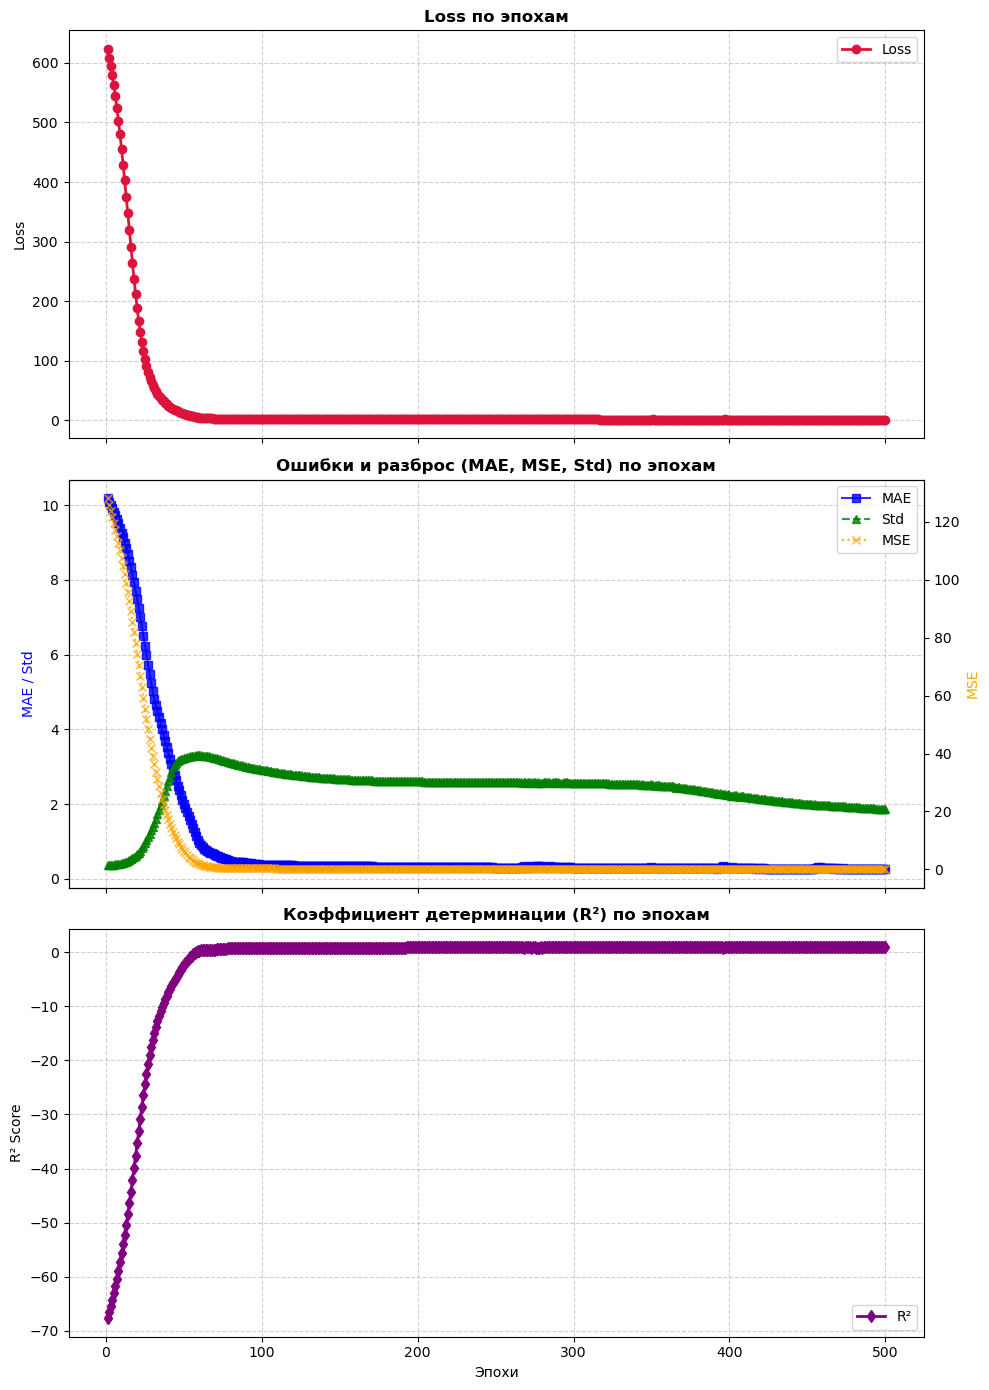

In [14]:
model, metrics = check_model_capacity(model_cls=ProbabilisticXANESResNet1D, 
                                      X_subset=X_train, 
                                      Y_subset=y_train,
                                      in_dim=141,
                                      num_outputs=n_out, 
                                      device=DEVICE, 
                                      num_epochs=500)

plot_metrics(metrics)

### MultiScaleXANESNet

Число параметров модели = 48441
🚀 Запуск теста емкости (проверяем MAE) на 128 примерах...
Epoch [1/500] | Loss: 622.0633| MAE: 10.188187| STD: 0.369383| R2: -67.721054
Epoch [50/500] | Loss: 4.7955| MAE: 1.018007| STD: 3.216047| R2: -0.209135
Epoch [100/500] | Loss: 4.4677| MAE: 0.949610| STD: 2.840762| R2: -0.128485
Epoch [150/500] | Loss: 4.3442| MAE: 0.936258| STD: 2.696931| R2: -0.087254
Epoch [200/500] | Loss: 4.0535| MAE: 0.899046| STD: 2.654984| R2: 0.031689
Epoch [250/500] | Loss: 3.7974| MAE: 0.882955| STD: 2.679096| R2: 0.031379
Epoch [300/500] | Loss: 3.1421| MAE: 0.833688| STD: 1.663503| R2: 0.251063
Epoch [350/500] | Loss: 2.5775| MAE: 0.767625| STD: 1.188399| R2: 0.351577
Epoch [400/500] | Loss: 2.4376| MAE: 0.760557| STD: 1.069530| R2: 0.379655
Epoch [450/500] | Loss: 3.5118| MAE: 0.876940| STD: 1.413898| R2: 0.046055
Epoch [500/500] | Loss: 2.8377| MAE: 0.817765| STD: 1.180615| R2: 0.279723
⚠️ ВНИМАНИЕ: MAE осталась высокой (MAE >= 0.05).


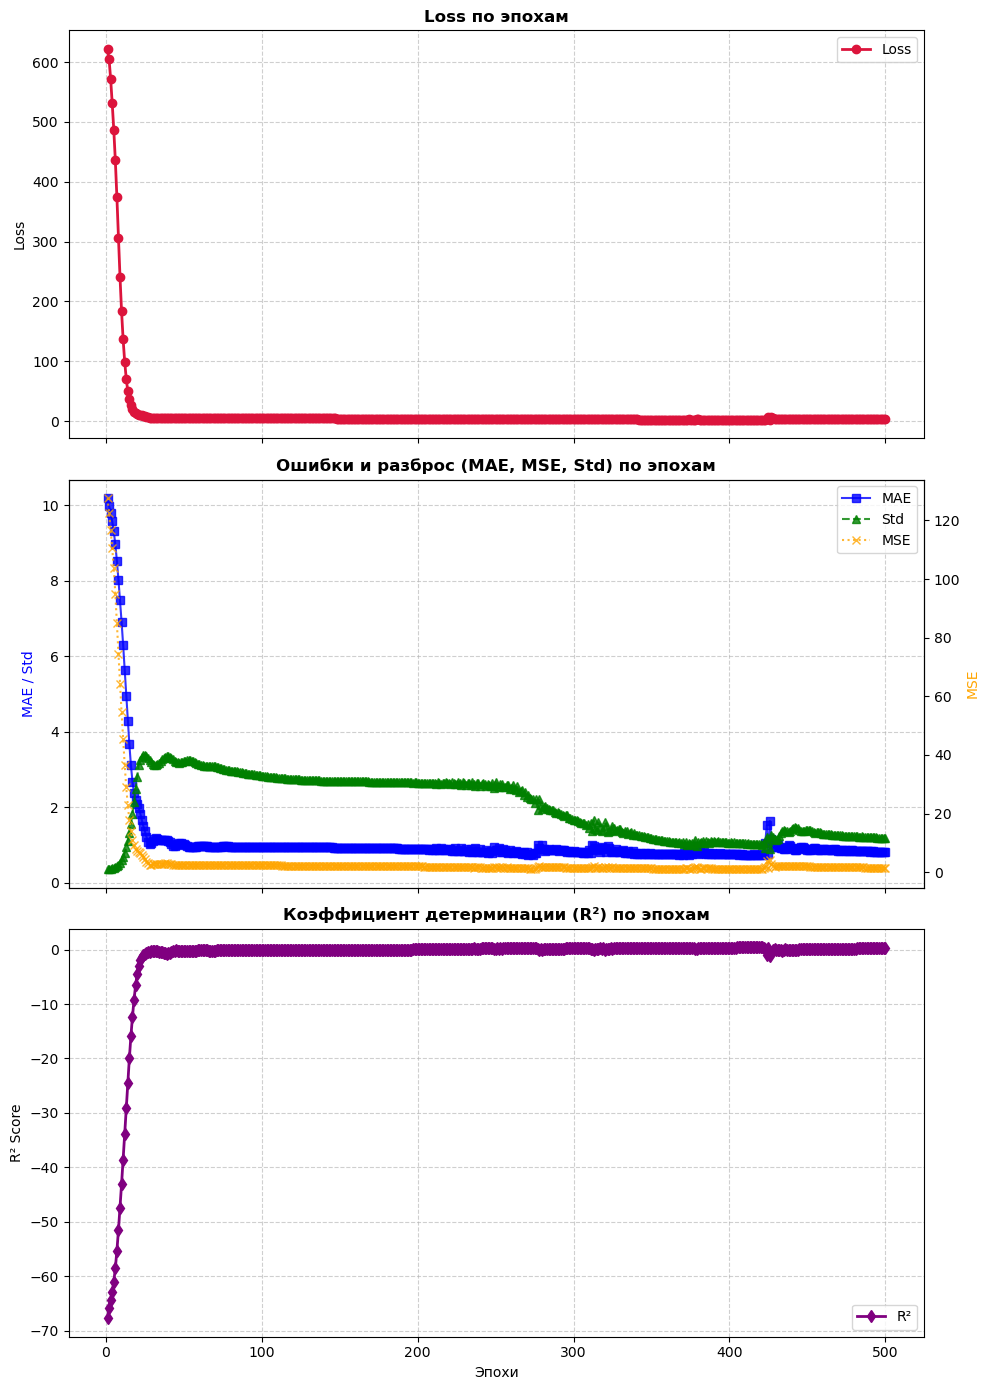

In [15]:
model, metrics = check_model_capacity(model_cls=MultiScaleXANESNet, 
                                      X_subset=X_train, 
                                      Y_subset=y_train,
                                      in_dim=141,
                                      num_outputs=n_out, 
                                      device=DEVICE, 
                                      num_epochs=500)

plot_metrics(metrics)

### XANES_CNN

Число параметров модели = 49608
🚀 Запуск теста емкости (проверяем MAE) на 128 примерах...
Epoch [1/500] | Loss: 625.1026| MAE: 10.111231| STD: 0.369630| R2: -67.551094
Epoch [50/500] | Loss: 3.9783| MAE: 0.897109| STD: 3.239632| R2: 0.012856
Epoch [100/500] | Loss: 2.6667| MAE: 0.677495| STD: 2.788224| R2: 0.529869
Epoch [150/500] | Loss: 1.5934| MAE: 0.452947| STD: 2.347283| R2: 0.775998
Epoch [200/500] | Loss: 0.9503| MAE: 0.356269| STD: 1.672542| R2: 0.861605
Epoch [250/500] | Loss: 0.3149| MAE: 0.300015| STD: 0.859623| R2: 0.891873
Epoch [300/500] | Loss: -0.1149| MAE: 0.289156| STD: 0.540516| R2: 0.899541
Epoch [350/500] | Loss: -0.4093| MAE: 0.237761| STD: 0.400904| R2: 0.930004
Epoch [400/500] | Loss: -0.5619| MAE: 0.205891| STD: 0.339905| R2: 0.942081
Epoch [450/500] | Loss: -0.7165| MAE: 0.191325| STD: 0.289556| R2: 0.948634
Epoch [500/500] | Loss: -0.5515| MAE: 0.194578| STD: 0.332303| R2: 0.948409
⚠️ ВНИМАНИЕ: MAE осталась высокой (MAE >= 0.05).


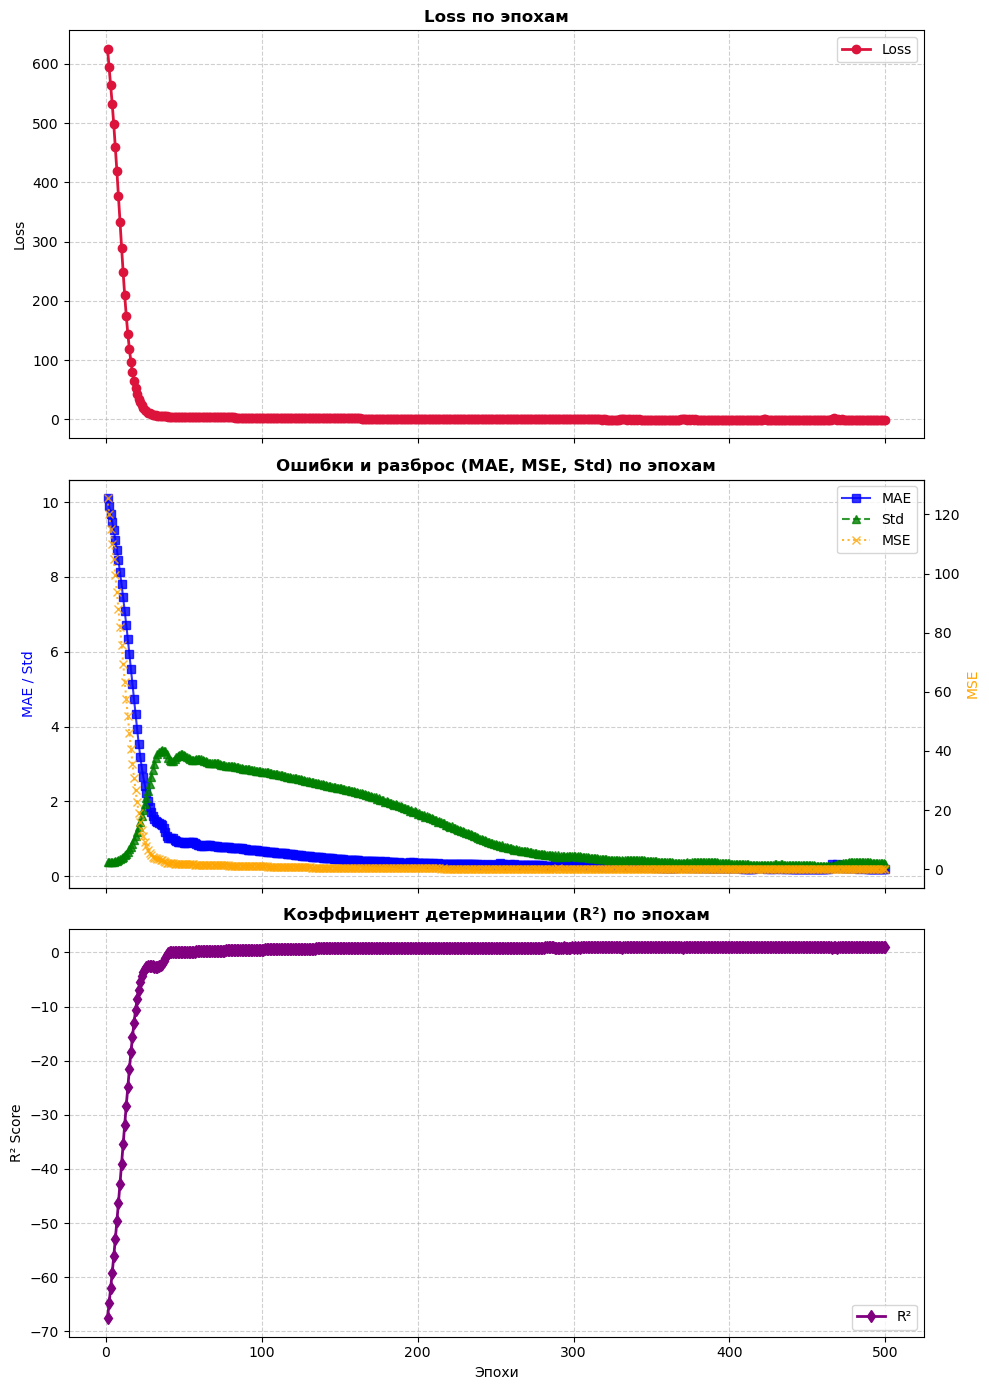

In [16]:
model, metrics = check_model_capacity(model_cls=XANES_CNN, 
                                      X_subset=X_train, 
                                      Y_subset=y_train,
                                      in_dim=141,
                                      num_outputs=n_out, 
                                      device=DEVICE, 
                                      num_epochs=500)

plot_metrics(metrics)

### XANES_CNN_Stable

Число параметров модели = 51720
🚀 Запуск теста емкости (проверяем MAE) на 128 примерах...
Epoch [1/500] | Loss: 622.0866| MAE: 10.079363| STD: 0.369392| R2: -66.424004
Epoch [50/500] | Loss: 4.2454| MAE: 1.007241| STD: 3.400063| R2: -0.487611
Epoch [100/500] | Loss: 2.5293| MAE: 0.666112| STD: 2.713891| R2: 0.530410
Epoch [150/500] | Loss: 1.5767| MAE: 0.424527| STD: 2.627753| R2: 0.798036
Epoch [200/500] | Loss: 1.3090| MAE: 0.344039| STD: 2.598571| R2: 0.861462
Epoch [250/500] | Loss: 1.2056| MAE: 0.313667| STD: 2.561713| R2: 0.882167
Epoch [300/500] | Loss: 1.0705| MAE: 0.294453| STD: 2.352045| R2: 0.896896
Epoch [350/500] | Loss: 0.6881| MAE: 0.285594| STD: 1.575229| R2: 0.906329
Epoch [400/500] | Loss: 0.1092| MAE: 0.256727| STD: 0.667593| R2: 0.919601
Epoch [450/500] | Loss: -0.3503| MAE: 0.240192| STD: 0.382137| R2: 0.928460
Epoch [500/500] | Loss: -0.0942| MAE: 0.221339| STD: 0.551731| R2: 0.938418
⚠️ ВНИМАНИЕ: MAE осталась высокой (MAE >= 0.05).


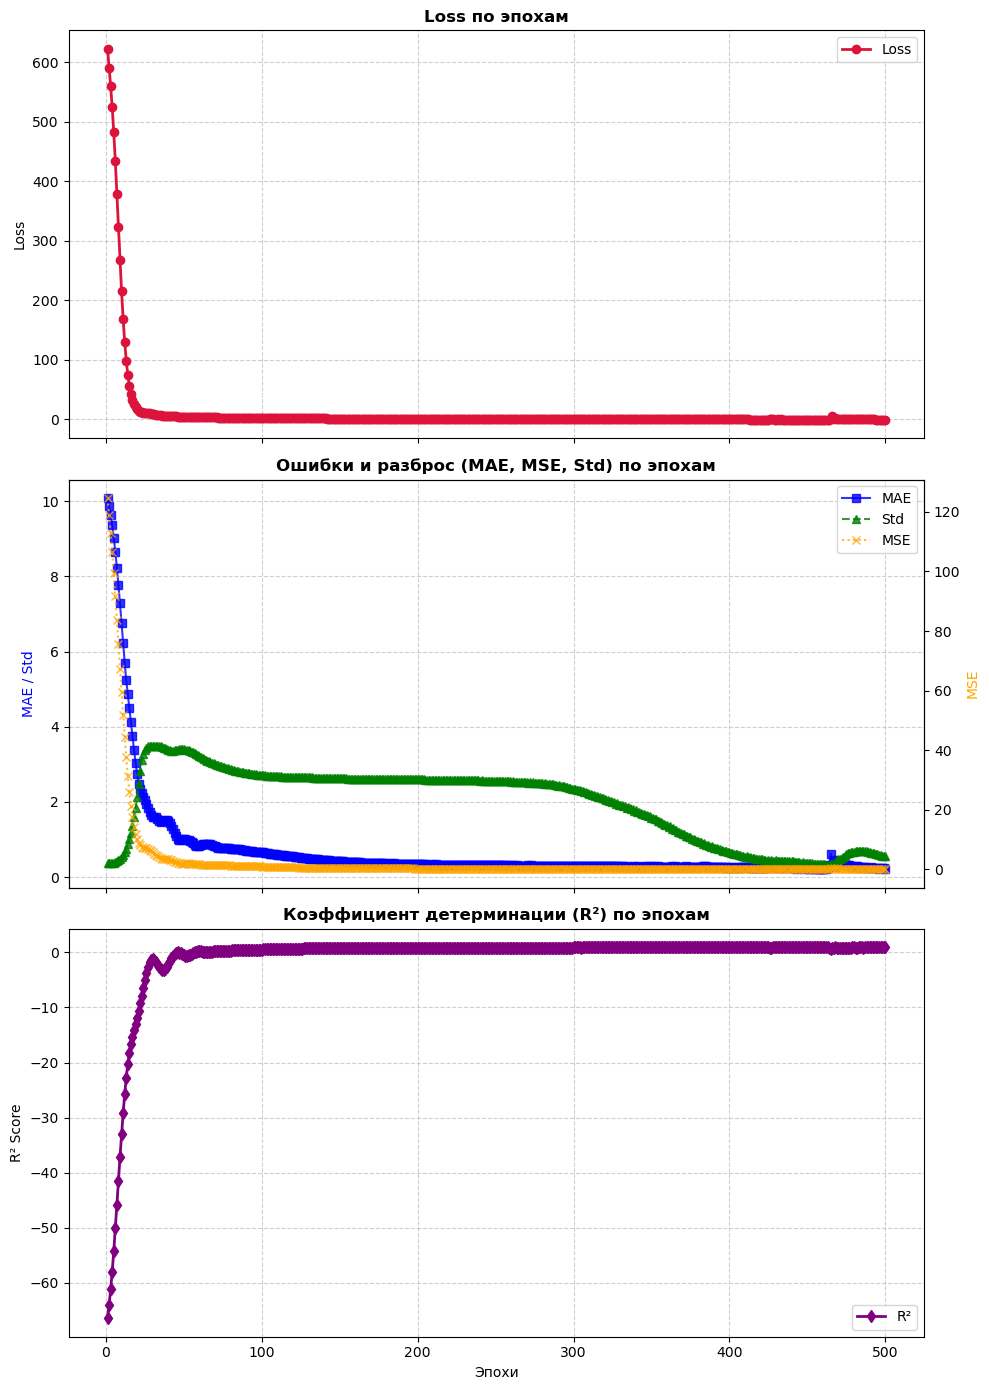

In [17]:
model, metrics = check_model_capacity(model_cls=XANES_CNN_Stable, 
                                      X_subset=X_train, 
                                      Y_subset=y_train,
                                      in_dim=141,
                                      num_outputs=n_out, 
                                      device=DEVICE, 
                                      num_epochs=500)

plot_metrics(metrics)

### XanesNN_JanisLike

Число параметров модели = 208214
🚀 Запуск теста емкости (проверяем MAE) на 128 примерах...
Epoch [1/500] | Loss: 637.7909| MAE: 9.109140| STD: 0.390781| R2: -54.693207
Epoch [50/500] | Loss: 4.4024| MAE: 0.984288| STD: 2.735884| R2: -0.139850
Epoch [100/500] | Loss: 3.9030| MAE: 0.905217| STD: 2.314300| R2: -0.007344
Epoch [150/500] | Loss: 3.7857| MAE: 0.910950| STD: 1.967860| R2: -0.004026
Epoch [200/500] | Loss: 3.7129| MAE: 0.910888| STD: 1.734627| R2: -0.003485
Epoch [250/500] | Loss: 3.6647| MAE: 0.910814| STD: 1.565549| R2: -0.002514
Epoch [300/500] | Loss: 3.6387| MAE: 0.910585| STD: 1.456111| R2: -0.000914
Epoch [350/500] | Loss: 3.6243| MAE: 0.909992| STD: 1.390778| R2: 0.002023
Epoch [400/500] | Loss: 3.6093| MAE: 0.908493| STD: 1.351683| R2: 0.008236
Epoch [450/500] | Loss: 3.5832| MAE: 0.904657| STD: 1.325208| R2: 0.020430
Epoch [500/500] | Loss: 3.5369| MAE: 0.897695| STD: 1.302028| R2: 0.042658
⚠️ ВНИМАНИЕ: MAE осталась высокой (MAE >= 0.05).


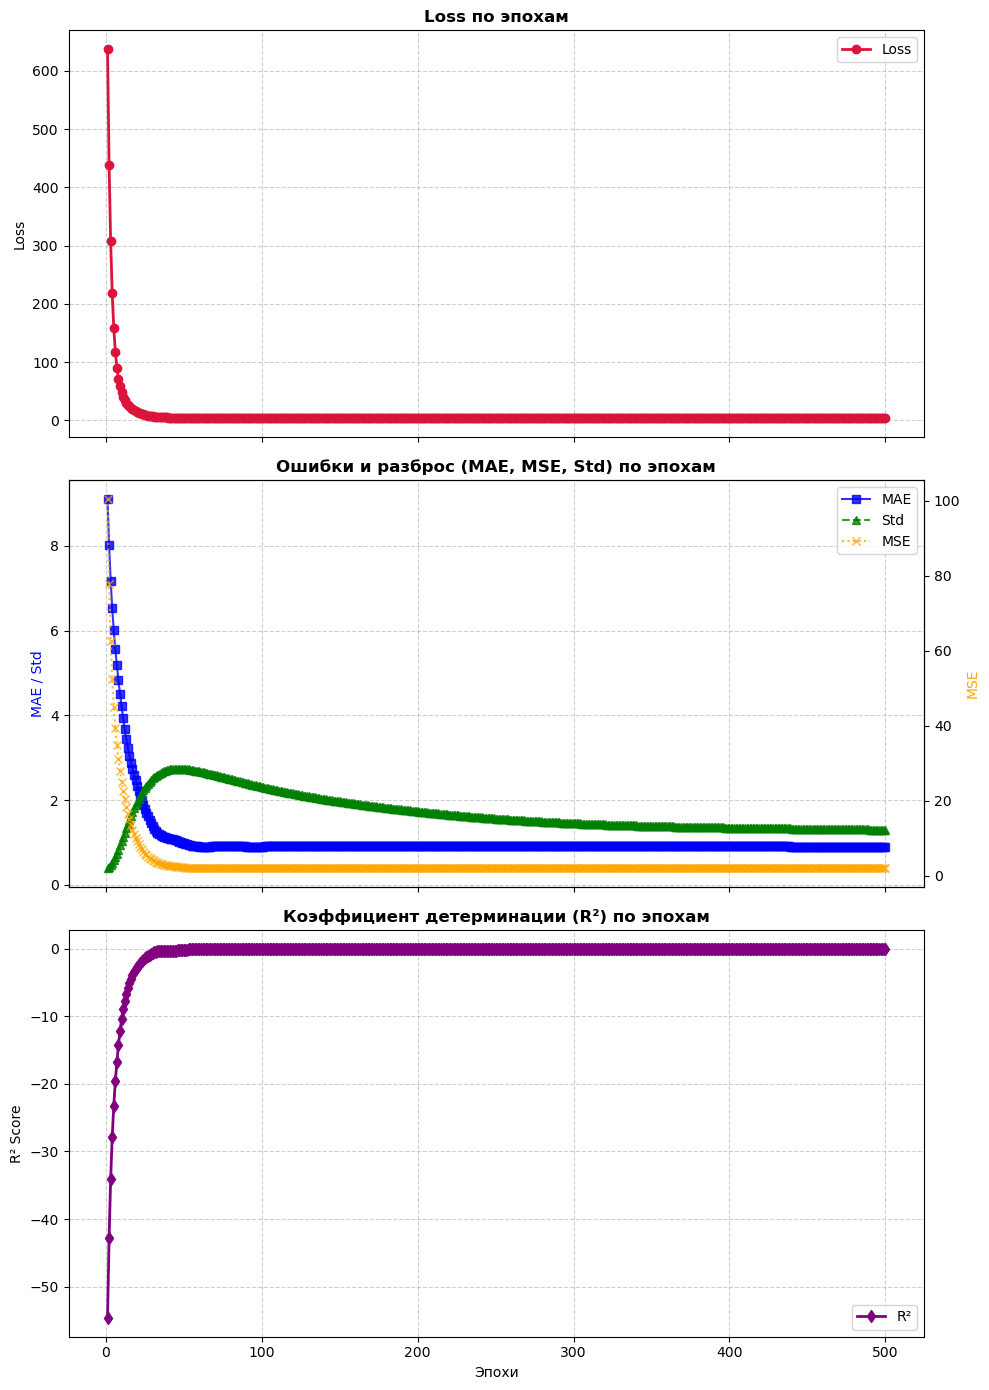

In [18]:
model, metrics = check_model_capacity(model_cls=XanesNN_JanisLike, 
                                      X_subset=X_train, 
                                      Y_subset=y_train,
                                      in_dim=141,
                                      num_outputs=n_out, 
                                      device=DEVICE, 
                                      num_epochs=500)

plot_metrics(metrics)

## Общие выводы

In [19]:
# ProbabilisticRegressionHead (-10,5) без особой инициализации.

# Предсказание 1 значения CN
# MLP при самом большом числе параметров демонстрирует наихудшие результаты по метрикам MSE, MAE, R2. (~200к параметров)
# MultiScaleXANESNet может выдавать хорошие результаты, но не стабильно, видимо сильно зависит от стартовой инициализации. (~50к параметров)
# Стандартная CNN выдает более точные результаты и делает это чуть стабильней при практически томже числе параметров (~50к параметров)
# ProbabilisticXANESResNet1D выдает наилучшие результаты и стабильность (~120к параметров)
# Достигаемые значение Mu ~ 0.05, Std ~ 0.15
# (Обучается <200 эпох) (изменения не значений функции потерь, а mu, std, mse, r2)

# Предсказание 4 значения CN
# MLP выдает хорошие значения MAE и значения для mu и std, однако R2<0.1. (видимо предсказывает просто средние значения?)
# MultiScaleXANESNet может выдавать хорошую точность, лучше чем CNN, но по прежнему не очень стабильно (может скатиться в большие std (1-8)).
# CNN выдает хорошие значения метрик с R2~0.92, однако тоже не очень стабильно.
# ProbabilisticXANESResNet1D выдает наилучшие результаты и стабильность (~120к параметров)
# Достигаемые средние значения  MAE~0.25, mu~0.2, std~0.3, R2~0.94
# (Обучается ~200-300 эпох)

# Быстрофикс - задать более жесткую инициализацию и границы для ProbabilisticRegressionHead (-6,2.5) стартовые веса (mu=1e-6, std=-1)
# Обучение MultiScaleXANESNet и CNN становится стабильней, но вместе с тем все модели немного терают в пиковой точности.
# Модели CNN при удачном старте могут выдавать лучшую точность, на уровне и ProbabilisticXANESResNet1D без ограничений.
# Обучение занимает около 300+ эпох.

# Имеет смысл остановиться на рассмотрении ProbabilisticXANESResNet1D или CNN. Предсказывать либо по 1 значению CN, либо до 4.